# Workflows & Analysis: Routing, Reliability & Data Volumes
*Fabian Nütz*

Once your network is declared, pandaict can compute a wide range of metrics. This notebook covers:

- **Link Usage Probability (LUP) tables** — which routes are available and how likely they are to be used
- **Deterministic reliability** — MTBF, MTTR, and BER along routes and LUP-weighted paths
- **App data volume** — how much data an app transmits over time
- **Teaser**: the Monte Carlo reliability engine

## Setup — build the example network from notebooks 02–03

In [62]:
import pandaict as pi
from   pandaict.utils.enums import NodeType, DeviceType, AppType, InfoItem, RoutingType, SortType
from   pandaict.plot import create_plot
import matplotlib.pyplot as plt

net = pi.create_empty_network(name='Analysis Demo')

n_core  = pi.create_ict_node(net, name='Core-Router',   node_type=NodeType.ROUTER, link_types=['Fiber','LAN1000'])
n_sw1   = pi.create_ict_node(net, name='Switch-1',      node_type=NodeType.SWITCH, link_types=['LAN1000'])
n_sw2   = pi.create_ict_node(net, name='Switch-2',      node_type=NodeType.SWITCH, link_types=['LAN1000'])
n_field = pi.create_ict_node(net, name='Field-Switch',   node_type=NodeType.SWITCH, link_types=['LAN1000'])

ctrl_server = pi.create_ict_device(net, name='CTRL-Server', device_type=DeviceType.SERVER)
rtu_a       = pi.create_ict_device(net, name='RTU-A',       device_type=DeviceType.RTU)
rtu_b       = pi.create_ict_device(net, name='RTU-B',       device_type=DeviceType.RTU)
(mon_dev, mon_app) = pi.create_ict_devapp(net, name='Monitoring',
                                          device_type=DeviceType.SERVER,
                                          app_type=AppType.WEBSERVER)

pi.create_ict_link(net, name='L-SW1-Core',   from_elt=n_sw1,        to_elt=[n_core],       link_type='LAN1000')
pi.create_ict_link(net, name='L-Core-SW2',   from_elt=n_core,       to_elt=[n_sw2],        link_type='LAN1000')
pi.create_ict_link(net, name='L-SW2-Field',  from_elt=n_sw2,        to_elt=[n_field],      link_type='LAN1000')
pi.create_ict_link(net, name='L-Field-SW1',  from_elt=n_field,      to_elt=[n_sw1],        link_type='LAN1000')
pi.create_ict_link(net, name='L-Core-CTRL',  from_elt=n_core,       to_elt=[ctrl_server],  link_type='LAN1000')
pi.create_ict_link(net, name='L-Field-RTU-A',from_elt=n_field,      to_elt=[rtu_a],        link_type='LAN1000')
pi.create_ict_link(net, name='L-Field-RTU-B',from_elt=n_field,      to_elt=[rtu_b],        link_type='LAN1000')
pi.create_ict_link(net, name='L-SW2-Mon',    from_elt=n_sw2,        to_elt=[mon_dev],      link_type='LAN1000')

app_ctrl = pi.create_ict_app(net, name='App-CTRL',  app_type=AppType.CLIENT,    device=ctrl_server)
app_rtua = pi.create_ict_app(net, name='App-RTU-A', app_type=AppType.WEBSERVER, device=rtu_a)
app_rtub = pi.create_ict_app(net, name='App-RTU-B', app_type=AppType.WEBSERVER, device=rtu_b)

conn_rtua = pi.create_ict_connection(net, name='CTRL-to-RTU-A',
    from_app=app_ctrl, to_app=app_rtua, protocol='TCP',
    info_items=[InfoItem.REQUEST, InfoItem.VALUE],
    peers=(app_ctrl, app_rtua), producer=[0, 1], prod_freq_ms=[1000,1000])

conn_rtub = pi.create_ict_connection(net, name='CTRL-to-RTU-B',
    from_app=app_ctrl, to_app=app_rtub, protocol='TCP',
    info_items=[InfoItem.REQUEST, InfoItem.VALUE],
    peers=(app_ctrl, app_rtub), producer=[0, 1], prod_freq_ms=[5000,5000])

print('Demo network ready.')

Demo network ready.


Here's the network overview again.

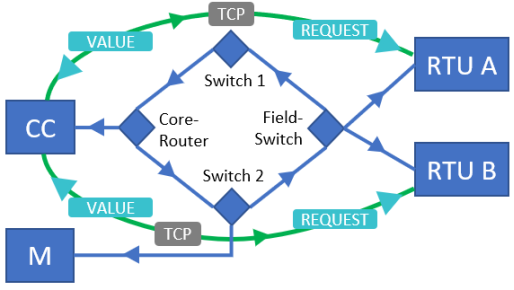

## App data volume

A very basic function that can be performed on the fully defined network is determining the data volume an app creates over a certain time. For this, all information items with known average send intervals sent by the app are evaluated. Send intervals and package size, as is defined by the protocol type, are used to calculate incoming data volume. Likewise, data volume for information items received from the peer app is calculated. 

In [29]:
from pandaict.topology.routing import calc_app_vol_MB

# Calculate total volume over 24 hours (86400 seconds)
vol = calc_app_vol_MB(net, app_ctrl, time_delta=86400)
print(f"App-CTRL data volume (down): {vol['total']['down']:.2f} MB")
print(f"App-CTRL data volume (up):   {vol['total']['up']:.2f} MB")

App-CTRL data volume (down): 2.07 MB
App-CTRL data volume (up):   2.07 MB


## LUP Table — Link Usage Probability

The LUP table enumerates routes (paths) for a connection, and attributes each with a probability weight. It is the foundation for most subsequent calculations. The calculation is done in downstream and upstream directions by default. The underlying routing algorithm is changeable; however, pandaict currently only supports lowest total latency. This means the calculation selects the routes with minimal total latency for both directions, and attributes them 100% probability. 

In [18]:
from pandaict.topology.routing import calc_lup_table
from pandaict.utils.utils import get_elt

lup = calc_lup_table(net, conn_rtua, routing_type=RoutingType.LOWEST_TOTAL_LATENCY, include_hops=True)

for i, route in enumerate(lup):
    print(f"Route {i}:")
    print(f" probability={route['probability']:.3f}")
    print(f" links={route['links']}")
    if 'hops' in route:
        hops = ""
        for hop in route['hops']:
            hops += get_elt(net, hop)['name']+" --- "
        print(f" hops = {hops[0:-4]}")

Route 0:
 probability=1.000
 links=[{'link': 4, 'downstream': False}, {'link': 1, 'downstream': True}, {'link': 2, 'downstream': True}, {'link': 5, 'downstream': True}]
 hops = CTRL-Server --- Core-Router --- Switch-2 --- Field-Switch --- RTU-A 
Route 1:
 probability=1.000
 links=[{'link': 5, 'downstream': False}, {'link': 3, 'downstream': True}, {'link': 0, 'downstream': True}, {'link': 4, 'downstream': True}]
 hops = RTU-A --- Field-Switch --- Switch-1 --- Core-Router --- CTRL-Server 


As seen, the function can return both nodes and devices on the route ("hops") as well as links used, together with the information in which direction they're used. 

## Sorted links by connection

The links involved in the routing paths of a connection can be obtained in sorted order, with sorting by various criteria:

In [20]:
from pandaict.topology.routing import calc_sorted_links_by_connection

print('By latency (ascending):')
sorted_down, sorted_up = calc_sorted_links_by_connection(net, conn_rtua, order=SortType.LATENCY)
for entry in sorted_down:
    print(f"  Route {entry["route"]} downstream: prob={entry["probability"]:.3f}")
    for link, val in zip(entry["links"], entry["values"]):
        name = net.link.loc[link["link"]]["name"]
        print(f"    {name}: {val:.2f} ms")

print('\nBy bandwidth (descending):')
sorted_down, _ = calc_sorted_links_by_connection(net, conn_rtua, order=SortType.BANDWIDTH, ascending=False)
for entry in sorted_down:
    print(f"  Route {entry["route"]} downstream: prob={entry["probability"]:.3f}")
    for link, val in zip(entry["links"], entry["values"]):
        name = net.link.loc[link["link"]]["name"]
        print(f"    {name}: {val:.1f} Mbps")

By latency (ascending):
  Route 0 downstream: prob=1.000
    L-Core-CTRL: 100.00 ms
    L-Core-SW2: 100.00 ms
    L-SW2-Field: 100.00 ms
    L-Field-RTU-A: 100.00 ms

By bandwidth (descending):
  Route 0 downstream: prob=1.000
    L-Core-CTRL: 1000.0 Mbps
    L-Core-SW2: 1000.0 Mbps
    L-SW2-Field: 1000.0 Mbps
    L-Field-RTU-A: 1000.0 Mbps


## Link bandwidth usage

The routing calculation is basis of different functions. One of those is calculating which data bandwidth is used per link for a given connection. Like the App data volume calculation, this function is based on information item payload and production frequency, but also takes the LUP table for the connection into account. This function helps to identify possible bandwith bottlenecks.

In [34]:
from pandaict.topology.routing import calc_link_bandwidth_Mbps

link_bw   = calc_link_bandwidth_Mbps(net, lup)
print(f"Link bandwidths for connection {lup.conn['name']}:")
for lid in link_bw.keys():
    print(f"Link {lid} bandwidth usage: {link_bw[lid][0]} Mbps (downstream), {link_bw[lid][1]} Mbps (upstream)")


Link bandwidths for connection CTRL-to-RTU-A:
Link 4 bandwidth usage: 0.00016 Mbps (downstream), 0.00016 Mbps (upstream)
Link 1 bandwidth usage: 0.00016 Mbps (downstream), 0 Mbps (upstream)
Link 2 bandwidth usage: 0.00016 Mbps (downstream), 0 Mbps (upstream)
Link 5 bandwidth usage: 0.00016 Mbps (downstream), 0.00016 Mbps (upstream)
Link 3 bandwidth usage: 0.00016 Mbps (downstream), 0 Mbps (upstream)
Link 0 bandwidth usage: 0.00016 Mbps (downstream), 0 Mbps (upstream)


## Deterministic reliability: MTBF, MTTR, BER

pandaict provides **deterministic** reliability calculations based on a serial-system model. For a single route (list of links), there are:

- `calc_mtbf_route()` — Mean Time Between Failure
- `calc_mtbf_mttr_route()` — both MTBF and MTTR
- `calc_ber_route()` — Bit Error Rate

These can also be LUP-weighted (taking all possible routes into account):
- `calc_mtbf_mttr_by_lup()`
- `calc_ber_by_lup()`

In case of our example, the nodes were created without reliability values, which means they never fail. However, the links all use the standard type TCP which has an MTBF of 8000 hours, an MTTR of 2 hours, and a BER of 2E-8 1/km. The BER values in the example are zero because the links were created without `length_km` parameter, which renders their length and BER zero by default.

In [54]:
from pandaict.reliability.mtbf_mttr import calc_mtbf_route, calc_mtbf_mttr_route, calc_mtbf_mttr_by_lup
from pandaict.reliability.ber import calc_ber_route, calc_ber_by_lup

# Get the first route and convert link dicts to element tuples
lup = calc_lup_table(net, conn_rtua, routing_type=RoutingType.LOWEST_TOTAL_LATENCY)
route_links = [("link", l["link"]) for l in lup.get_route(0)["links"]]
print('Route links:', [(net.link.loc[l[1]]['name']) for l in route_links])

Route links: ['L-Core-CTRL', 'L-Core-SW2', 'L-SW2-Field', 'L-Field-RTU-A']


In [59]:
# Single-route calculations
mtbf = calc_mtbf_route(net, route_links)
mtbf_mttr = calc_mtbf_mttr_route(net, route_links)
ber = calc_ber_route(net, route_links)

print(f"Route MTBF:  {mtbf:.1f} h")
print(f"Route MTBF:  {mtbf_mttr[0]:.1f} h  (serial model, links + nodes)")
print(f"Route MTTR:  {mtbf_mttr[1]:.1f} h")
print(f"Route BER:   {ber:.8e}")

Route MTBF:  2000.0 h
Route MTBF:  2000.0 h  (serial model, links + nodes)
Route MTTR:  2.0 h
Route BER:   0.00000000e+00


In [60]:
# LUP-weighted calculations (consider all possible routes)
lup = calc_lup_table(net, conn_rtua, routing_type=RoutingType.LOWEST_TOTAL_LATENCY)
lup_result = calc_mtbf_mttr_by_lup(net, lup)
lup_ber    = calc_ber_by_lup(net, lup)

print(f"LUP-weighted MTBF: {lup_result[0]:.1f} h")
print(f"LUP-weighted MTTR: {lup_result[1]:.1f} h")
print(f"LUP-weighted BER:  {lup_ber:.8e}")

LUP-weighted MTBF: 2000.0 h
LUP-weighted MTTR: 2.0 h
LUP-weighted BER:  0.00000000e+00


## Bonus: Monte Carlo reliability (teaser)

The deterministic model above treats the network as a simple serial system. For non-trivial topologies with redundancy, the **Monte Carlo engine** simulates stochastic failure/repair events and gives more accurate estimates. However, routing is not taken into consideration here: the engine assumes by default that a connection only fails if all possible routes fail. A dedicated tutorial series covers this in depth.

In [61]:
from pandaict.reliability.reliability import estimate_mtbf_mttr_for_conn

# The Monte Carlo approach captures the ring redundancy
mc_result = estimate_mtbf_mttr_for_conn(net, [conn_rtua])
print(f"Monte Carlo MTBF: {mc_result["mtbf_h"]:.1f} h")
print(f"Monte Carlo MTTF: {mc_result["mttf_h"]:.1f} h")
print(f"Monte Carlo MTTR: {mc_result["mttr_h"]:.1f} h")


Running 20000000 (100000 x 200) simulations in parallel...
Monte Carlo MTBF: 3997.0 h
Monte Carlo MTTF: 3995.0 h
Monte Carlo MTTR: 2.0 h


## Summary

| Capability | Function(s) |
|------------|-------------|
| Route enumeration | `calc_lup_table()` |
| Link sorting | `calc_sorted_links_by_connection()` |
| Deterministic reliability | `calc_mtbf_route()`, `calc_mtbf_mttr_route()`, `calc_mtbf_mttr_by_lup()` |
| Bit error rate | `calc_ber_route()`, `calc_ber_by_lup()` |
| Data volume | `calc_app_vol_MB()` |
| Monte Carlo reliability | `estimate_mttf_mttr_for_conn()` (separate tutorial series) |

Next: [05 – Inspection & Management](05_inspection_management.ipynb)